In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix


from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, HistGradientBoostingClassifier)

In [ ]:
CSV_COLLISION = "dft-road-casualty-statistics-collision-1979-latest-published-year.csv"
CSV_VEHICLE   = "dft-road-casualty-statistics-vehicle-1979-latest-published-year.csv"
CSV_CASUALTY  = "dft-road-casualty-statistics-casualty-1979-latest-published-year.csv"

MIN_YEAR = 2019   


def read_filtered(path, cols, keep_ids=None, min_year=None):
    parts = []
    for chunk in pd.read_csv(path, usecols=cols, chunksize=500_000):
        if min_year is not None:
            chunk = chunk[chunk["collision_year"] >= min_year]
        if keep_ids is not None:
            chunk = chunk[chunk["collision_index"].isin(keep_ids)]
        parts.append(chunk)
    return pd.concat(parts, ignore_index=True)

In [ ]:

collision_cols = [
    "collision_index", "collision_year", "collision_severity", "number_of_vehicles",
    "date", "day_of_week", "time", "first_road_class", "road_type", "speed_limit",
    "junction_detail", "junction_control", "pedestrian_crossing", "light_conditions",
    "weather_conditions", "road_surface_conditions", "urban_or_rural_area", "trunk_road_flag",
]

collisions = read_filtered(CSV_COLLISION, collision_cols, min_year=MIN_YEAR)
keep_ids = set(collisions["collision_index"])
print(collisions.shape)

(722536, 18)


In [ ]:
df_3 = read_filtered(CSV_VEHICLE, ["collision_index", "vehicle_type", "age_of_driver"], keep_ids)
df_3.shape()
vehicles = read_filtered(CSV_VEHICLE, ["collision_index", "vehicle_type", "age_of_driver"], keep_ids)

vehicles["age_of_driver"] = vehicles["age_of_driver"].where(vehicles["age_of_driver"] >= 0)  # -1 means missing

# flag each vehicle type, then add them up per collision
vt = vehicles["vehicle_type"]
vehicles["n_motorcycles"] = vt.isin([2, 3, 4, 5, 23, 97]).astype(int)
vehicles["n_cars"]        = (vt == 9).astype(int)
vehicles["n_vans"]        = (vt == 19).astype(int)
vehicles["n_hgv"]         = vt.isin([20, 21, 98]).astype(int)
vehicles["n_buses"]       = vt.isin([10, 11]).astype(int)
vehicles["n_cyclists"]    = (vt == 1).astype(int)

vehicle_summary = vehicles.groupby("collision_index").agg(
    n_motorcycles=("n_motorcycles", "sum"),
    n_cars=("n_cars", "sum"),
    n_vans=("n_vans", "sum"),
    n_hgv=("n_hgv", "sum"),
    n_buses=("n_buses", "sum"),
    n_cyclists=("n_cyclists", "sum"),
    youngest_driver=("age_of_driver", "min"),
    oldest_driver=("age_of_driver", "max"),
).reset_index()
print(vehicle_summary.shape)

(722536, 9)


In [ ]:
# Casualty table (many rows per collision)
casualty_cols = ["collision_index", "casualty_class", "sex_of_casualty", "age_of_casualty"]
casualties = read_filtered(CSV_CASUALTY, casualty_cols, keep_ids)

casualties["age_of_casualty"] = casualties["age_of_casualty"].where(casualties["age_of_casualty"] >= 0)

casualties["is_pedestrian"] = (casualties["casualty_class"] == 3).astype(int)
casualties["is_male"]       = (casualties["sex_of_casualty"] == 1).astype(int)
casualties["is_female"]     = (casualties["sex_of_casualty"] == 2).astype(int)
casualties["is_child"]      = (casualties["age_of_casualty"] < 16).astype(int)


casualty_summary = casualties.groupby("collision_index").agg(
    n_casualties=("casualty_class", "size"),
    n_pedestrian_casualties=("is_pedestrian", "sum"),
    n_male_casualties=("is_male", "sum"),
    n_female_casualties=("is_female", "sum"),
    n_child_casualties=("is_child", "sum"),
    youngest_casualty=("age_of_casualty", "min"),
    oldest_casualty=("age_of_casualty", "max"),
).reset_index()
print(casualty_summary.shape)

(722536, 8)


In [22]:
df = collisions.merge(vehicle_summary, on="collision_index", how="left")
df = df.merge(casualty_summary, on="collision_index", how="left")

print(df.shape)
assert len(df) == len(collisions)   # make sure the merge did not create extra rows

(722536, 33)


In [23]:
# -1 means "missing" in this dataset (except junction_control where it means no junction)
cols_to_clean = [c for c in df.columns if c != "junction_control"]
df[cols_to_clean] = df[cols_to_clean].replace(-1, np.nan)

# 99 means "unknown" in these two columns
for col in ["junction_detail", "pedestrian_crossing"]:
    df[col] = df[col].replace(99, np.nan)

# which columns have the most missing values?
(df.isna().mean() * 100).sort_values(ascending=False).head(10)

trunk_road_flag            7.339288
oldest_driver              5.164033
youngest_driver            5.164033
pedestrian_crossing        3.948731
junction_detail            3.365645
youngest_casualty          1.578745
oldest_casualty            1.578745
road_surface_conditions    0.573259
speed_limit                0.013148
light_conditions           0.004982
dtype: float64

In [24]:
# New features from date and time
df["hour"]         = pd.to_datetime(df["time"], format="%H:%M", errors="coerce").dt.hour
df["month"]        = pd.to_datetime(df["date"], format="%d/%m/%Y", errors="coerce").dt.month
df["is_weekend"]   = df["day_of_week"].isin([1, 7]).astype(int)    # 1 = Sunday, 7 = Saturday
df["is_rush_hour"] = df["hour"].isin([7, 8, 9, 16, 17, 18]).astype(int)

df = df.drop(columns=["date", "time"])
df.shape

(722536, 35)

collision_severity
3    0.766
2    0.219
1    0.015
Name: proportion, dtype: float64


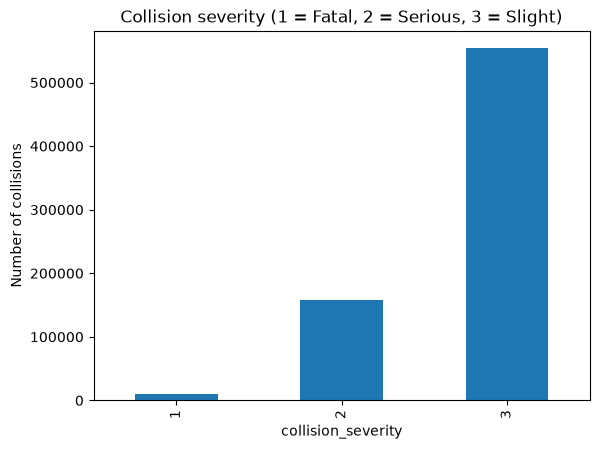

In [25]:
print(df["collision_severity"].value_counts(normalize=True).round(3))

df["collision_severity"].value_counts().sort_index().plot(kind="bar")
plt.title("Collision severity (1 = Fatal, 2 = Serious, 3 = Slight)")
plt.ylabel("Number of collisions")
plt.show()

In [26]:
y = df["collision_severity"]
X = df.drop(columns=["collision_severity", "collision_index", "collision_year"])

# trees can't handle NaN in some models, so fill with -1
X = X.fillna(-1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(578028, 32) (144508, 32)


In [27]:
# use a sample of the training data so the models are lighter and faster
X_small = X_train.sample(200_000, random_state=42)
y_small = y_train.loc[X_small.index]

models = {
    "Decision Tree (baseline)": DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=42),
    "Bagging":                  BaggingClassifier(
                                    estimator=DecisionTreeClassifier(max_depth=15, min_samples_leaf=20),
                                    n_estimators=30, n_jobs=1, random_state=42),
    "Random Forest":            RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_leaf=20,
                                                       class_weight="balanced", n_jobs=2, random_state=42),
    "Extra Trees":              ExtraTreesClassifier(n_estimators=100, max_depth=15, min_samples_leaf=20,
                                                     class_weight="balanced", n_jobs=2, random_state=42),
    "AdaBoost":                 AdaBoostClassifier(n_estimators=100, random_state=42),
    "Hist Gradient Boosting":   HistGradientBoostingClassifier(max_iter=200, class_weight="balanced",
                                                               random_state=42),
}

results = []
trained = {}

for name, model in models.items():
    print("Training", name, "...")
    model.fit(X_small, y_small)
    pred = model.predict(X_test)

    trained[name] = model
    results.append({
        "model": name,
        "accuracy": round(accuracy_score(y_test, pred), 3),
        "macro_f1": round(f1_score(y_test, pred, average="macro"), 3),
    })

results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
results_df

Training Decision Tree (baseline) ...
Training Bagging ...
Training Random Forest ...
Training Extra Trees ...
Training AdaBoost ...
Training Hist Gradient Boosting ...


,model,accuracy,macro_f1
0,Random Forest,0.578,0.403
1,Hist Gradient Boosting,0.577,0.399
2,Extra Trees,0.594,0.396
3,Decision Tree (baseline),0.528,0.368
4,Bagging,0.772,0.361
5,AdaBoost,0.768,0.309


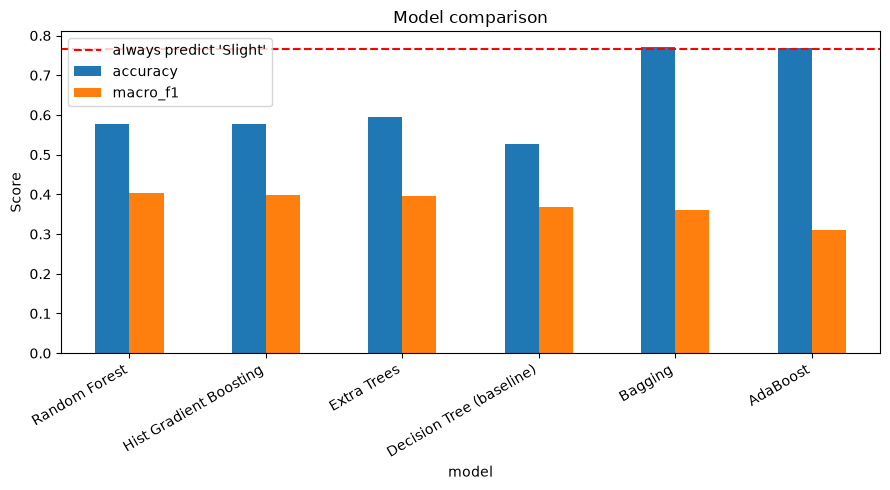

In [28]:
# plot the comparison
results_df.set_index("model")[["accuracy", "macro_f1"]].plot(kind="bar", figsize=(9, 5))
plt.title("Model comparison")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.axhline(0.766, color="red", linestyle="--", label="always predict 'Slight'")
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
best_name = results_df.loc[0, "model"]
best_model = trained[best_name]
print("Best model (by macro F1):", best_name)

best_pred = best_model.predict(X_test)
print(classification_report(y_test, best_pred))

Best model (by macro F1): Random Forest
              precision    recall  f1-score   support

           1       0.07      0.61      0.12      2120
           2       0.31      0.46      0.37     31630
           3       0.87      0.61      0.72    110758

    accuracy                           0.58    144508
   macro avg       0.42      0.56      0.40    144508
weighted avg       0.74      0.58      0.63    144508



[[ 1297   641   182]
 [ 7136 14640  9854]
 [11235 31878 67645]]


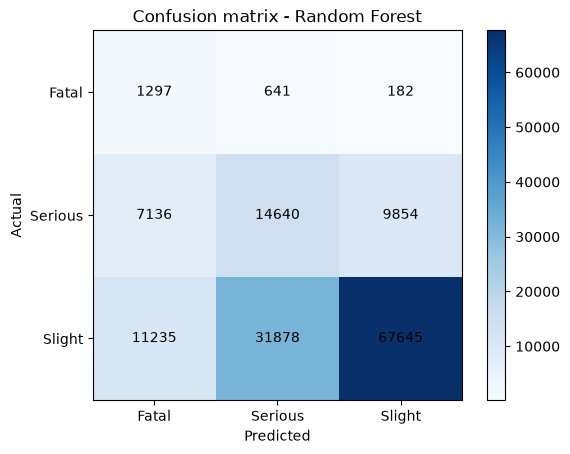

In [30]:
cm = confusion_matrix(y_test, best_pred)
print(cm)

plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks([0, 1, 2], ["Fatal", "Serious", "Slight"])
plt.yticks([0, 1, 2], ["Fatal", "Serious", "Slight"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix - " + best_name)
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.show()

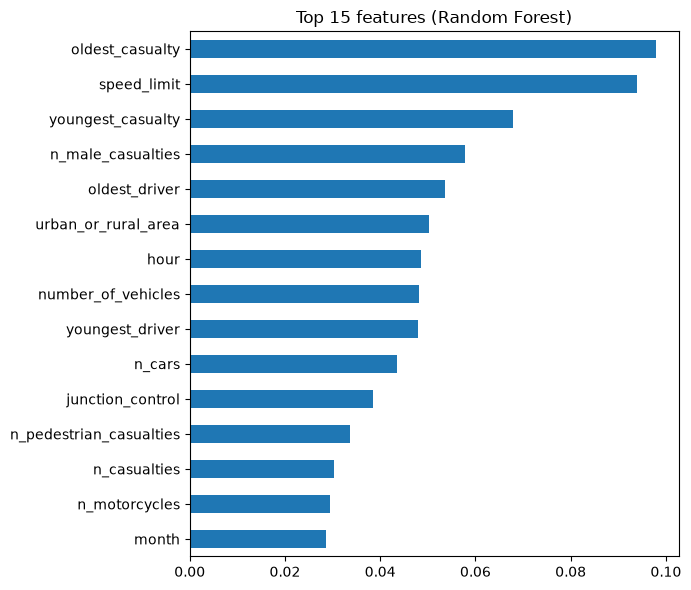

In [31]:
# Random Forest has feature_importances_ so use it to see important features
rf = trained["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

importance.head(15).sort_values().plot(kind="barh", figsize=(7, 6))
plt.title("Top 15 features (Random Forest)")
plt.tight_layout()
plt.show()